# Hybrid Movie Recommender: MovieLens 25M + IMDb + TMDB (PySpark)
Predicts user ratings and ranks movies, comparing simple baselines, ALS collaborative filtering, and a hybrid gradient-boosted-trees (GBT) model. Every model is scored on a held-out test set, and all features are built from training data only.

## 1. Data check
Loads the ratings table and checks its size and rating distribution. The user-movie matrix is about 99.7% empty, so the task is predicting unobserved ratings from limited signal.

In [0]:
from pyspark.sql import functions as F

ratings = spark.table("workspace.default.ratings_clean").select("userId","movieId","rating","timestamp")
print("ratings:", ratings.count())
print("users:", ratings.select("userId").distinct().count())
print("movies:", ratings.select("movieId").distinct().count())
ratings.groupBy("rating").count().orderBy("rating").show()

ratings: 25000095
users: 162541
movies: 59047
+------+-------+
|rating|  count|
+------+-------+
|   0.5| 393068|
|   1.0| 776815|
|   1.5| 399490|
|   2.0|1640868|
|   2.5|1262797|
|   3.0|4896928|
|   3.5|3177318|
|   4.0|6639798|
|   4.5|2200539|
|   5.0|3612474|
+------+-------+



## 2. Frozen train/test split
Samples 10% of users, then splits their ratings 80/20. The split is saved as tables and reloaded on later runs so the test set never changes.

In [0]:
SAMPLE_FRAC, SEED = 0.10, 42
T, V = "workspace.default.train_ratings", "workspace.default.test_ratings"

if spark.catalog.tableExists(T) and spark.catalog.tableExists(V):
    print("Frozen split found; loading it.")
else:
    sampled = ratings.join(
        ratings.select("userId").distinct().sample(False, SAMPLE_FRAC, seed=SEED), "userId")
    tr, te = sampled.randomSplit([0.8, 0.2], seed=SEED)
    tr.write.mode("overwrite").saveAsTable(T)
    te.write.mode("overwrite").saveAsTable(V)

train, test = spark.table(T), spark.table(V)
print(train.count(), test.count())     # expect 2019443 504298

Frozen split found; loading it.
2019443 504298


## 3. Baselines
**Metrics:** RMSE penalizes large misses; MAE is the average miss in stars. The global mean (predict the training average for everyone) is the floor every model must beat.

In [0]:
from pyspark.ml.evaluation import RegressionEvaluator

def evaluate(df, label="rating", pred="prediction"):
    out = {}
    for m in ["rmse", "mae"]:
        out[m] = RegressionEvaluator(labelCol=label, predictionCol=pred, metricName=m).evaluate(df)
    return out

global_mean = train.agg(F.avg("rating")).first()[0]
b1 = test.withColumn("prediction", F.lit(float(global_mean)))
print("Global mean:", evaluate(b1))

Global mean: {'rmse': 1.060856932205035, 'mae': 0.841378096312955}


### User + movie bias baseline
Predicts global mean + movie offset + user offset (how well liked a movie is, how generous a user is). Offsets are shrunk toward zero for rarely-rated movies and users. A strong baseline with no machine learning.

In [0]:
mu = float(train.agg(F.avg("rating")).first()[0])
LAMBDA = 10   # shrinkage strength

# Movie bias: average deviation from the global mean, shrunk for rarely-rated movies
movie_b = (train.groupBy("movieId")
    .agg((F.sum(F.col("rating") - mu) / (F.count("*") + LAMBDA)).alias("b_i")))

# User bias: average leftover deviation after removing the movie effect
tr = train.join(movie_b, "movieId", "left")
user_b = (tr.groupBy("userId")
    .agg((F.sum(F.col("rating") - mu - F.col("b_i")) / (F.count("*") + LAMBDA)).alias("b_u")))

# Predict on test; unseen users or movies get bias 0, so they fall back to the mean
pred_bias = (test.join(movie_b, "movieId", "left").join(user_b, "userId", "left")
    .fillna({"b_i": 0.0, "b_u": 0.0})
    .withColumn("prediction",
        F.least(F.lit(5.0), F.greatest(F.lit(0.5), F.lit(mu) + F.col("b_i") + F.col("b_u")))))

print("Bias baseline:", evaluate(pred_bias))

Bias baseline: {'rmse': 0.8605115921779839, 'mae': 0.6566424013656884}


## 4. ALS collaborative filtering
Learns hidden taste factors for each user and movie (rank 20, regularization 0.1). Users or movies unseen in training are dropped (cold start), so ALS is scored on slightly fewer rows.

In [0]:
from pyspark.ml.recommendation import ALS

als = ALS(userCol="userId", itemCol="movieId", ratingCol="rating",
          rank=20, regParam=0.1, maxIter=10,
          coldStartStrategy="drop", seed=42)

als_model = als.fit(train)                       # learn the hidden factors from training data
pred_als = als_model.transform(test)             # predict unseen test ratings

# Clip into the valid rating range, same as the bias baseline
pred_als = pred_als.withColumn("prediction",
    F.least(F.lit(5.0), F.greatest(F.lit(0.5), F.col("prediction"))))

print("Test rows:", test.count(), "| ALS scored rows:", pred_als.count())
print("ALS:", evaluate(pred_als))

Test rows: 504298 | ALS scored rows: 501693
ALS: {'rmse': 0.8116880364712141, 'mae': 0.6279422797706516}


Rescores the bias baseline on exactly the rows ALS predicted, so the comparison is like-for-like.

In [0]:
pred_bias_same = pred_bias.join(pred_als.select("userId", "movieId"), ["userId", "movieId"])
print("Bias baseline on the same rows:", evaluate(pred_bias_same))

Bias baseline on the same rows: {'rmse': 0.8604631624601689, 'mae': 0.6570169579129035}


## 5. Leakage-safe features
User and movie averages come from training data only. For training rows, each row's own rating is removed from its features (leave-one-out), so features never contain the label. Averages are shrunk toward the global mean (K=5). IMDb/TMDB features get missing-value flags.

In [0]:
mu = float(train.agg(F.avg("rating")).first()[0])
K = 5

u_stats = train.groupBy("userId").agg(F.sum("rating").alias("u_sum"), F.count("*").alias("u_cnt"))
m_stats = train.groupBy("movieId").agg(F.sum("rating").alias("m_sum"), F.count("*").alias("m_cnt"))

meta = (spark.table("workspace.default.unified_movie_metadata_final_clean")
        .select("movieId","imdb_rating","imdb_votes","tmdb_vote_average",
                "tmdb_vote_count","tmdb_popularity","year")
        .dropDuplicates(["movieId"]))      # one row per movie, so joins don't multiply ratings

def build(df, is_train):
    d = (df.join(u_stats, "userId", "left")
           .join(m_stats, "movieId", "left")
           .join(meta, "movieId", "left"))
    r = F.col("rating")
    zero = F.lit(0.0)
    if is_train:   # leave-one-out: remove this row's own rating
        u_sum, u_cnt = F.col("u_sum") - r, F.col("u_cnt") - 1
        m_sum, m_cnt = F.col("m_sum") - r, F.col("m_cnt") - 1
    else:          # test rows: unseen users/movies get zero counts
        u_sum, u_cnt = F.coalesce("u_sum", zero), F.coalesce("u_cnt", zero)
        m_sum, m_cnt = F.coalesce("m_sum", zero), F.coalesce("m_cnt", zero)

    d = (d.withColumn("u_avg", (u_sum + K*mu) / (u_cnt + K))
          .withColumn("u_logcnt", F.log1p(u_cnt))
          .withColumn("m_avg", (m_sum + K*mu) / (m_cnt + K))
          .withColumn("m_logcnt", F.log1p(m_cnt)))

    # Missing metadata: add a flag so the model knows it was missing, then fill with 0
    for c in ["imdb_rating","imdb_votes","tmdb_vote_average","tmdb_vote_count","tmdb_popularity","year"]:
        d = d.withColumn(c + "_missing", F.col(c).isNull().cast("double"))
        d = d.withColumn(c, F.coalesce(F.col(c).cast("double"), zero))
    return d

train_f = build(train, True)
test_f  = build(test, False)
print(train_f.count(), test_f.count())    # should equal 2019443 and 504298

2019443 504298


Saves the built features so a session timeout doesn't force a rebuild.

In [0]:
train_f.write.mode("overwrite").saveAsTable("workspace.default.train_features")
test_f.write.mode("overwrite").saveAsTable("workspace.default.test_features")

train_f = spark.table("workspace.default.train_features")
test_f  = spark.table("workspace.default.test_features")

## 6. Hybrid GBT: averages + IMDb/TMDB metadata
A team of 50 decision trees (depth 5), each correcting the errors of the previous ones. The train-vs-test gap shows whether it overfits.

In [0]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import GBTRegressor
from pyspark.ml import Pipeline

feat_cols = ["u_avg","u_logcnt","m_avg","m_logcnt",
             "imdb_rating","imdb_votes","tmdb_vote_average","tmdb_vote_count",
             "tmdb_popularity","year",
             "imdb_rating_missing","tmdb_vote_average_missing","year_missing"]

gbt = GBTRegressor(featuresCol="features", labelCol="rating",
                   maxDepth=5, maxBins=64, maxIter=50, seed=42)
pipe = Pipeline(stages=[VectorAssembler(inputCols=feat_cols, outputCol="features"), gbt])

gbt_model = pipe.fit(train_f)                       # learn from training rows only

def score(df, name):
    p = gbt_model.transform(df).withColumn("prediction",
        F.least(F.lit(5.0), F.greatest(F.lit(0.5), F.col("prediction"))))
    print(name, evaluate(p))
    return p

pred_gbt   = score(test_f,  "GBT test: ")
_          = score(train_f, "GBT train:")     # train vs test gap shows overfitting

GBT test:  {'rmse': 0.866953519188762, 'mae': 0.6601680210201057}
GBT train: {'rmse': 0.8651437853163026, 'mae': 0.6586818978897196}


### Ablation: averages only
Same model with only the four average features, to measure what the external metadata adds.

In [0]:
core = ["u_avg", "u_logcnt", "m_avg", "m_logcnt"]
gbt_a = GBTRegressor(featuresCol="features", labelCol="rating",
                     maxDepth=5, maxBins=64, maxIter=50, seed=42)
model_a = Pipeline(stages=[VectorAssembler(inputCols=core, outputCol="features"), gbt_a]).fit(train_f)
pred_a = model_a.transform(test_f).withColumn("prediction",
    F.least(F.lit(5.0), F.greatest(F.lit(0.5), F.col("prediction"))))
print("GBT, averages only:", evaluate(pred_a))

GBT, averages only: {'rmse': 0.8688968802811706, 'mae': 0.6620013862755687}


## 7. Personalization: user-genre affinity
How much a user rates this movie's genres above or below their own average, built with the same leave-one-out and shrinkage rules, so it is leakage-safe.

In [0]:
movies = spark.table("workspace.default.movies_clean").select("movieId", "genres")
mg = (movies.withColumn("genre", F.explode(F.split("genres", r"\|")))
            .filter(F.col("genre") != "(no genres listed)")
            .select("movieId", "genre"))                      # one row per (movie, genre)

# Per user and genre: total rating and count, from training ratings only
ug = (train.join(mg, "movieId")
           .groupBy("userId", "genre")
           .agg(F.sum("rating").alias("ug_sum"), F.count("*").alias("ug_cnt")))

def add_affinity(df_f, is_train):
    x = (df_f.select("userId", "movieId", "rating", "u_avg")
             .join(mg, "movieId")
             .join(ug, ["userId", "genre"], "left"))
    r, zero = F.col("rating"), F.lit(0.0)
    if is_train:    # leave-one-out: remove this row's own rating
        s, c = F.col("ug_sum") - r, F.col("ug_cnt") - 1
    else:           # test rows: unseen user-genre pairs get zero counts
        s, c = F.coalesce("ug_sum", zero), F.coalesce("ug_cnt", zero)
    # How far this user's genre average sits from their overall average, shrunk by K
    x = x.withColumn("g_aff", (s - c * F.col("u_avg")) / (c + K))
    aff = x.groupBy("userId", "movieId").agg(F.avg("g_aff").alias("genre_aff"))   # average over the movie's genres
    return df_f.join(aff, ["userId", "movieId"], "left").fillna({"genre_aff": 0.0})

train_g = add_affinity(train_f, True)
test_g  = add_affinity(test_f, False)
print(train_g.count(), test_g.count())     # must still be 2019443 and 504298

2019443 504298


Saves the affinity features.

In [0]:
train_g.write.mode("overwrite").saveAsTable("workspace.default.train_features_g")
test_g.write.mode("overwrite").saveAsTable("workspace.default.test_features_g")
train_g = spark.table("workspace.default.train_features_g")
test_g  = spark.table("workspace.default.test_features_g")

Same GBT settings as above, plus the genre-affinity feature.

In [0]:
cols_g = feat_cols + ["genre_aff"]
gbt_g = GBTRegressor(featuresCol="features", labelCol="rating",
                     maxDepth=5, maxBins=64, maxIter=50, seed=42)
model_g = Pipeline(stages=[VectorAssembler(inputCols=cols_g, outputCol="features"), gbt_g]).fit(train_g)

pred_g = model_g.transform(test_g).withColumn("prediction",
    F.least(F.lit(5.0), F.greatest(F.lit(0.5), F.col("prediction"))))
print("GBT + genre affinity:", evaluate(pred_g))

GBT + genre affinity: {'rmse': 0.8498186426473188, 'mae': 0.6479711813863615}


## 8. Ranking metrics
For each user with at least 10 test ratings, ranks their held-out movies by each model's score. **Precision@10** is the share of the top 10 rated 4.0 or higher; **NDCG@10** rewards placing higher-rated movies nearer the top (1.0 is perfect). Popularity (training rating count) is the non-personalized reference. This re-ranks held-out rated items, not the full catalog.

In [0]:
from pyspark.sql.window import Window

common = pred_als.select("userId", "movieId")        # same rows for every model (ALS drops cold-start rows)
eligible = test.groupBy("userId").count().filter(F.col("count") >= 10).select("userId")

def prep(df):
    return df.select("userId", "movieId", "rating", "prediction").join(common, ["userId", "movieId"])

def rank_metrics(df, k=10, thresh=4.0):
    d = df.join(eligible, "userId")
    w_pred = Window.partitionBy("userId").orderBy(F.desc("prediction"), "movieId")
    w_true = Window.partitionBy("userId").orderBy(F.desc("rating"), "movieId")
    d = (d.withColumn("r_pred", F.row_number().over(w_pred))     # position by the model
          .withColumn("r_true", F.row_number().over(w_true)))    # position in the ideal order
    per_user = d.groupBy("userId").agg(
        F.sum(F.when(F.col("r_pred") <= k, F.col("rating") / F.log2(F.col("r_pred") + 1))).alias("dcg"),
        F.sum(F.when(F.col("r_true") <= k, F.col("rating") / F.log2(F.col("r_true") + 1))).alias("idcg"),
        F.sum(F.when((F.col("r_pred") <= k) & (F.col("rating") >= thresh), 1.0).otherwise(0.0)).alias("hits"))
    row = per_user.select(F.avg(F.col("dcg") / F.col("idcg")).alias("ndcg"),
                          F.avg(F.col("hits") / k).alias("precision")).first()
    return {"NDCG@10": round(row["ndcg"], 4), "Precision@10": round(row["precision"], 4)}

pop = test_g.select("userId", "movieId", "rating",
                    F.coalesce(F.col("m_cnt"), F.lit(0)).cast("double").alias("prediction"))

models = {"Popularity": pop, "User+movie bias": pred_bias,
          "GBT + genre affinity": pred_g, "ALS": pred_als}

for name, df in models.items():
    print(name, rank_metrics(prep(df)))

Popularity {'NDCG@10': 0.8576, 'Precision@10': 0.6334}
User+movie bias {'NDCG@10': 0.8873, 'Precision@10': 0.6966}
GBT + genre affinity {'NDCG@10': 0.8949, 'Precision@10': 0.7054}
ALS {'NDCG@10': 0.9157, 'Precision@10': 0.7391}


## 9. Error analysis
Test-set error histogram and average predicted-vs-actual rating. Both models drift toward the middle: they over-predict low ratings and under-predict high ones.

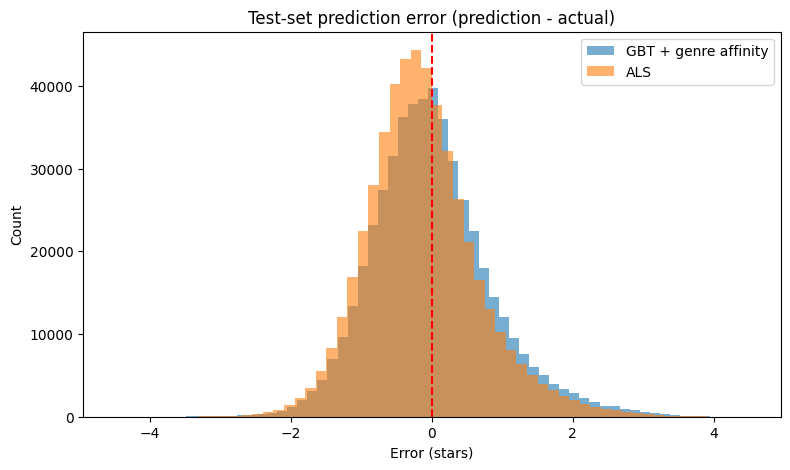

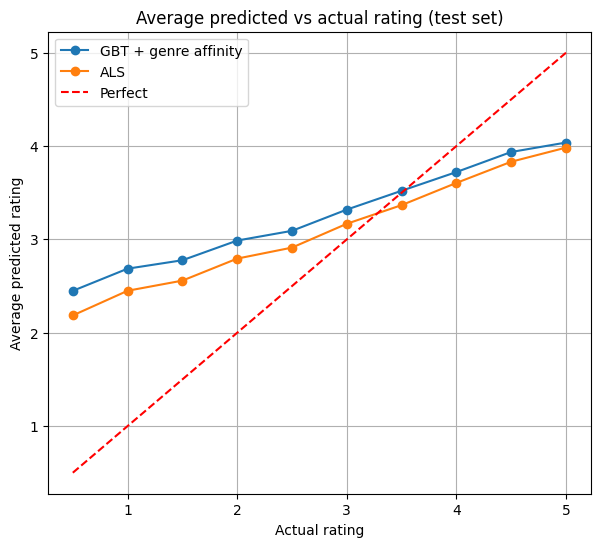

In [0]:
spark.sql("CREATE VOLUME IF NOT EXISTS workspace.default.results")
out = "/Volumes/workspace/default/results"

import matplotlib.pyplot as plt

gbt_pdf = pred_g.select("rating", "prediction").toPandas()
als_pdf = pred_als.select("rating", "prediction").toPandas()
for d in (gbt_pdf, als_pdf):
    d["error"] = d["prediction"] - d["rating"]

# Figure 1: error distributions on the test set
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(gbt_pdf["error"], bins=60, alpha=0.6, label="GBT + genre affinity")
ax.hist(als_pdf["error"], bins=60, alpha=0.6, label="ALS")
ax.axvline(0, color="red", linestyle="--")
ax.set(title="Test-set prediction error (prediction - actual)", xlabel="Error (stars)", ylabel="Count")
ax.legend()
fig.savefig(f"{out}/error_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 2: average prediction for each true rating
fig, ax = plt.subplots(figsize=(7, 6))
for d, name in [(gbt_pdf, "GBT + genre affinity"), (als_pdf, "ALS")]:
    g = d.groupby("rating")["prediction"].mean()
    ax.plot(g.index, g.values, marker="o", label=name)
ax.plot([0.5, 5], [0.5, 5], "r--", label="Perfect")
ax.set(title="Average predicted vs actual rating (test set)", xlabel="Actual rating", ylabel="Average predicted rating")
ax.legend(); ax.grid(True)
fig.savefig(f"{out}/predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

## Results (10% user sample, 504,298 test ratings)

| Model | RMSE | MAE | NDCG@10 | Precision@10 |
|---|---|---|---|---|
| Global mean | 1.061 | 0.841 | – | – |
| Popularity | – | – | 0.858 | 0.633 |
| User + movie bias | 0.861 | 0.657 | 0.887 | 0.697 |
| GBT, averages only | 0.869 | 0.662 | – | – |
| GBT, + IMDb/TMDB metadata | 0.867 | 0.660 | – | – |
| GBT, + metadata + genre affinity | 0.850 | 0.648 | 0.895 | 0.705 |
| **ALS (rank 20, untuned)** | **0.812** | **0.628** | **0.916** | **0.739** |

**Findings**
- IMDb/TMDB metadata improved RMSE by only ~0.2% once user and movie averages were known.
- A leakage-safe genre-affinity feature gave a ~2% gain, roughly nine times larger, so personalization mattered far more than external metadata.
- The best hybrid beat the bias baseline (0.850 vs 0.861) but not ALS, which was ~4.5% better on rating error and also led on both ranking metrics.
- A popularity baseline ranked worst, and well-liked movies (bias model) beat merely well-known ones.

**Limitations**
- 10% user sample; random (not time-based) split.
- ALS is untuned and scored on 99.5% of test rows (unseen users/movies are dropped).
- Ranking re-ranks each user's held-out rated items, so absolute NDCG is not comparable to full-catalog results.
- IMDb/TMDB scores reflect current opinion, not opinion at the time of each rating.
- GBT scores can shift in the third decimal between runs (distributed training is not fully deterministic); differences below ~0.002 RMSE should not be over-interpreted.